# Data inspection


In [26]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image


### 0. Wczytanie datasetu

In [34]:
DATA_ROOT = PROJECT_DIR / 'data' / 'raw' / 'archive'
DATASET_DIR = DATA_ROOT / 'DATASET'
TRAIN_DIR = DATASET_DIR / 'train'
TEST_DIR = DATASET_DIR / 'test'

for folder in (TRAIN_DIR, TEST_DIR):
    if not folder.is_dir():
        raise FileNotFoundError(f'Directory not found: {folder}')

print('Dataset:', DATA_ROOT)

Dataset: /Users/anielka/facial_expression-recognition/data/raw/archive


### 1. Wyświetlenie struktury folderów



In [28]:
print(DATA_ROOT.name + "/")

for path in sorted(DATA_ROOT.rglob("*")): #rglob() - zwraca wszystkie pliki i foldery w katalogu i jego podkatalogach
    if path.is_dir():
        depth = len(path.relative_to(DATA_ROOT).parts) #parts - zwraca krotkę z częściami ścieżki
        print("    " * depth + path.name + "/")

archive/
    DATASET/
        test/
            1/
            2/
            3/
            4/
            5/
            6/
            7/
        train/
            1/
            2/
            3/
            4/
            5/
            6/
            7/


### 2. Lokalizacja zdjęć i etykiet


In [29]:
#define the mapping of label numbers to emotion names
EMOTIONS = {
    1: "surprise",
    2: "fear",
    3: "disgust",
    4: "happiness",
    5: "sadness",
    6: "anger",
    7: "neutral"
}

#load labels
train = pd.read_csv(DATA_ROOT / "train_labels.csv")
test = pd.read_csv(DATA_ROOT / "test_labels.csv")

train["split"] = "train"
test["split"] = "test"

#combine labels and map emotions
labels = pd.concat([train, test], ignore_index=True) #concat - łączy dwa DataFrame'y w jeden, ignorując indeksy

labels["emotion"] = labels["label"].astype(int).map(EMOTIONS) #map - zastępuje wartości w kolumnie wartościami z słownika

display(labels.head())

,image,label,split,emotion
0,train_00001_aligned.jpg,5,train,sadness
1,train_00002_aligned.jpg,5,train,sadness
2,train_00003_aligned.jpg,4,train,happiness
3,train_00004_aligned.jpg,4,train,happiness
4,train_00005_aligned.jpg,5,train,sadness


### 3. Liczba zdjęć i dostępne klasy

In [30]:
# Count images and inspect classes
records = []

for split in ["train", "test"]:
    for path in (DATASET_DIR / split).rglob("*"): #rglob() - zwraca wszystkie pliki i foldery w katalogu i jego podkatalogach
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "split": split,
                "image": path.name,
                "folder_label": path.parent.name, #parent - zwraca katalog nadrzędny
                "path": path
            })

images = pd.DataFrame(records)



#Check image counts and classes

for split in ["train", "test"]:
    subset = images[images["split"] == split]

    print(f"{split}:")
    print("Images:", len(subset))
    print("CSV labels:", (labels["split"] == split).sum())
    print("Classes:", sorted(subset["folder_label"].unique()))
    print()

train:
Images: 12271
CSV labels: 12271
Classes: ['1', '2', '3', '4', '5', '6', '7']

test:
Images: 3068
CSV labels: 3068
Classes: ['1', '2', '3', '4', '5', '6', '7']



### 4. Przykładowe zdjęcia z każdej emocji

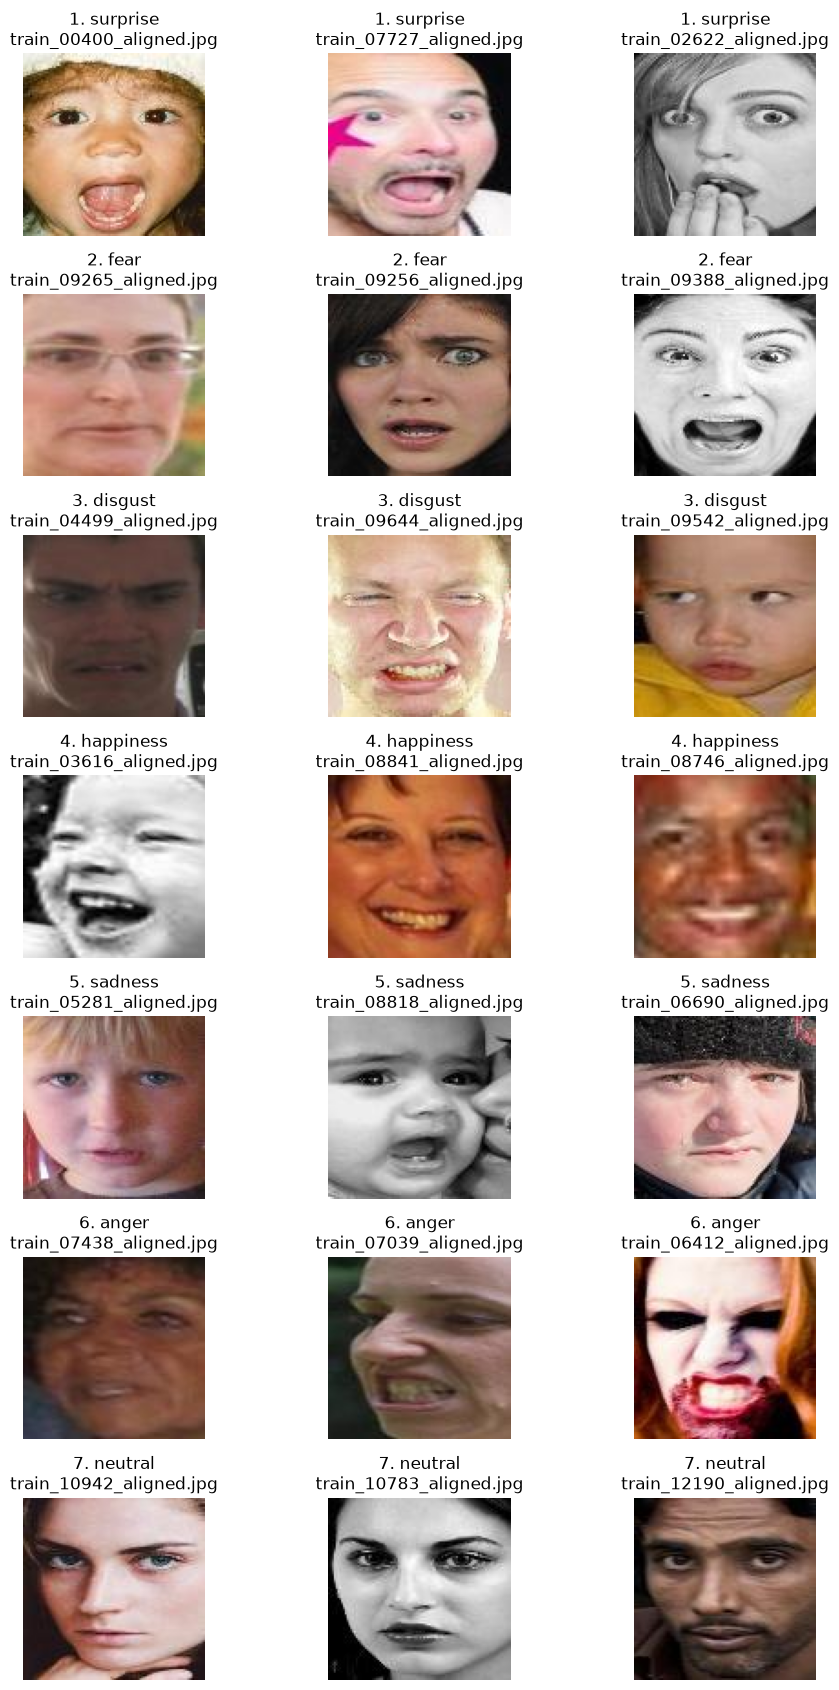

In [31]:
fig, axes = plt.subplots(7, 3, figsize=(10, 17))

for ax in axes.flat:
    ax.axis("off")

for row, (label, emotion) in enumerate(EMOTIONS.items()):

    subset = images[
        (images["split"] == "train") &
        (images["folder_label"] == str(label))
    ]

    examples = subset.sample(n=min(3, len(subset)), random_state=42)

    for col, path in enumerate(examples["path"]):
        with Image.open(path) as img:
            axes[row, col].imshow(img.convert("RGB"))
        axes[row, col].set_title(f"{label}. {emotion}\n{path.name}")

plt.tight_layout()
plt.show()

### 5. Format, rozdzielczość i kanały kolorów

In [32]:
properties = []
damaged_files = []

for path in images["path"]:
    try:
        with Image.open(path) as img:
            img.load()

            properties.append({
                "format": img.format,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "channels": len(img.getbands())
            })

    except (OSError, ValueError, SyntaxError, Image.DecompressionBombError):
        damaged_files.append(path)


image_info = pd.DataFrame(properties)

print("Valid images:", len(image_info))
print("Damaged images:", len(damaged_files))

display(
    image_info.groupby(
        ["format", "width", "height", "mode", "channels"]
    ).size().reset_index(name="count")
)

Valid images: 15339
Damaged images: 0


,format,width,height,mode,channels,count
0,JPEG,100,100,RGB,3,15339


### 6. Liczba zdjęć każdej emocji i wykres

split,train,test,total
emotion,,,
surprise,1290,329,1619
fear,281,74,355
disgust,717,160,877
happiness,4772,1185,5957
sadness,1982,478,2460
anger,705,162,867
neutral,2524,680,3204


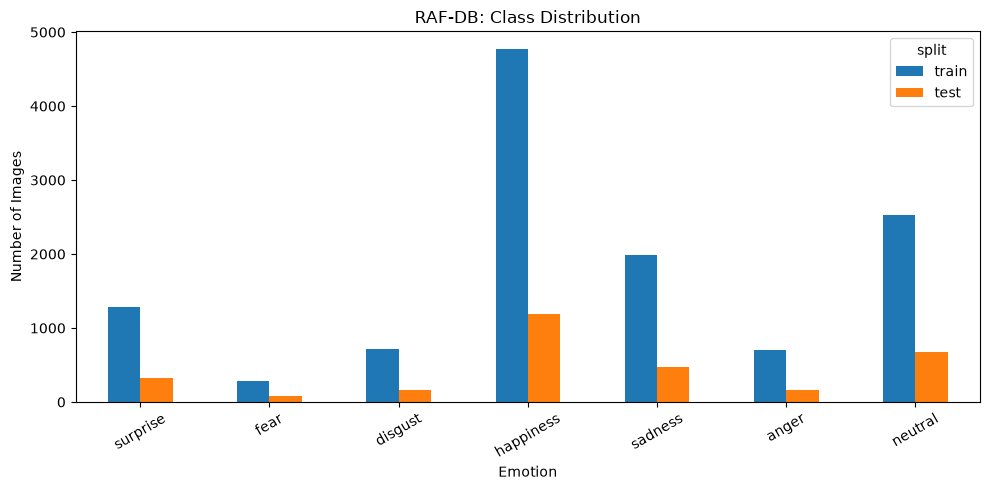

In [33]:
#Class distribution
images["emotion"] = images["folder_label"].astype(int).map(EMOTIONS)

counts = pd.crosstab(images["emotion"], images["split"])
counts = counts.reindex(
    index=list(EMOTIONS.values()),
    columns=["train", "test"],
    fill_value=0
)

counts["total"] = counts.sum(axis=1)

display(counts)

# Plot class distribution

counts[["train", "test"]].plot.bar(figsize=(10, 5))

plt.title("RAF-DB: Class Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()